Image size: (1096, 2147, 3)
RGB value: [237 202 170]


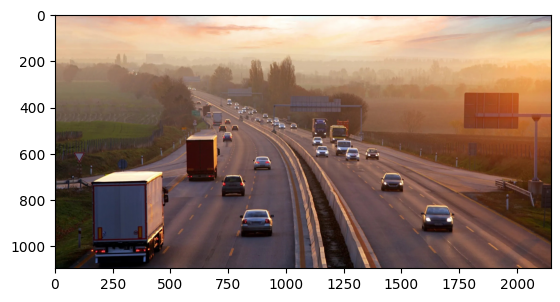

In [51]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

img = Image.open('traffic.jpeg')
img_array = np.array(img)
print("Image size:", img_array.shape)
pixel = img_array[100,150]
print("RGB value:", pixel)
plt.imshow(img_array)
plt.show()




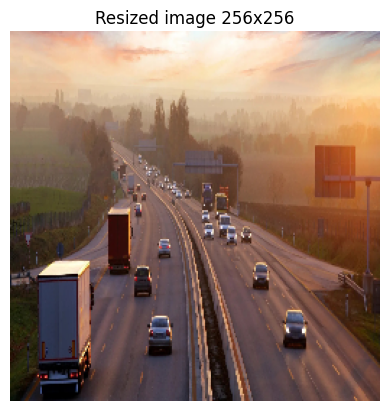

Gray pixel value at row 150 column 100 is 204


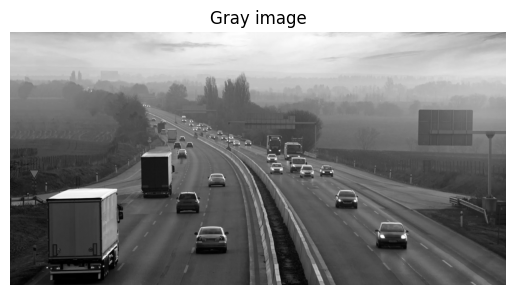

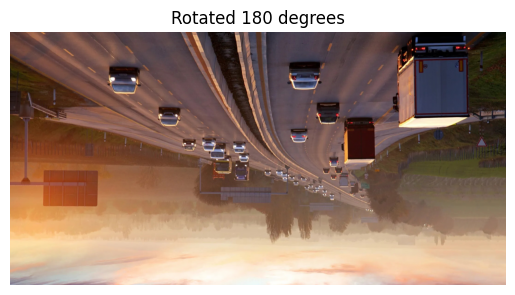

In [52]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('traffic.jpeg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

#Resize to 256x256
resized = cv2.resize(img_rgb, (256, 256))
plt.imshow(resized)
plt.title("Resized image 256x256")
plt.axis("off")
plt.show()

#RGB to gray at row 150 column 100
gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
pixel_gray = gray[150, 100]
print("Gray pixel value at row 150 column 100 is", pixel_gray)
plt.imshow(gray, cmap='gray')
plt.title("Gray image")
plt.axis("off")
plt.show()

#Rotate 180 degrees
rotated = cv2.rotate(img_rgb, cv2.ROTATE_180)
plt.imshow(rotated)
plt.title("Rotated 180 degrees")
plt.axis("off")
plt.show()


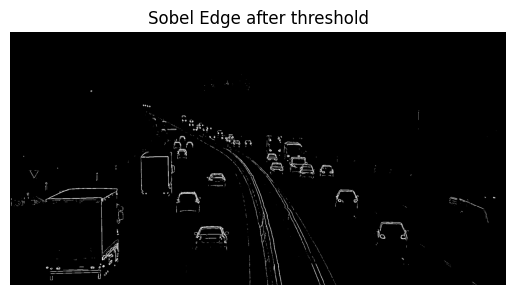

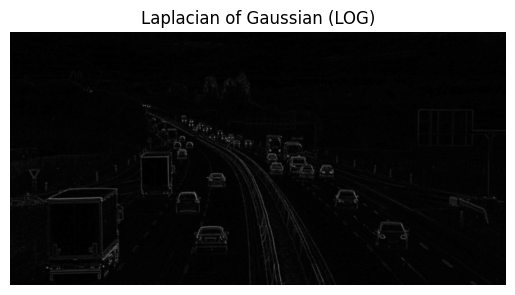

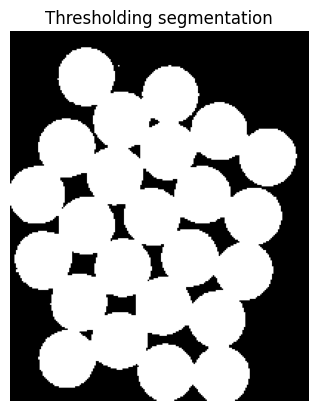

In [97]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('traffic.jpeg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#Sobel edge
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.sqrt(sobel_x**2 + sobel_y**2)
sobel_mag = np.uint8(255 * sobel_mag / np.max(sobel_mag))
_, sobel_thresh = cv2.threshold(sobel_mag, 50, 255, cv2.THRESH_BINARY)
plt.imshow(sobel_thresh, cmap='gray')
plt.title("Sobel Edge after threshold")
plt.axis("off")
plt.show()

#LOG
blur = cv2.GaussianBlur(gray, (5, 5), 0)
log = cv2.Laplacian(blur, cv2.CV_64F)
log_abs = np.uint8(np.absolute(log))
plt.imshow(log_abs, cmap='gray')
plt.title("Laplacian of Gaussian (LOG)")
plt.axis("off")
plt.show()

#3b
coins_bgr = cv2.imread("coins.jpeg")
coins_gray = cv2.cvtColor(coins_bgr, cv2.COLOR_BGR2GRAY)

_, coins_thresh = cv2.threshold(
    coins_gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

plt.imshow(coins_thresh, cmap="gray")
plt.title("Thresholding segmentation")
plt.axis("off")
plt.show()


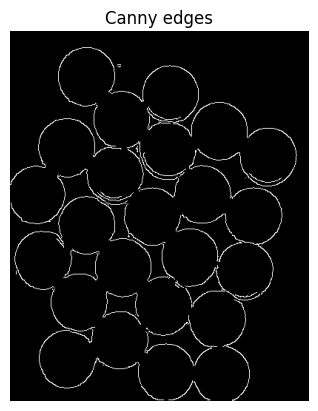

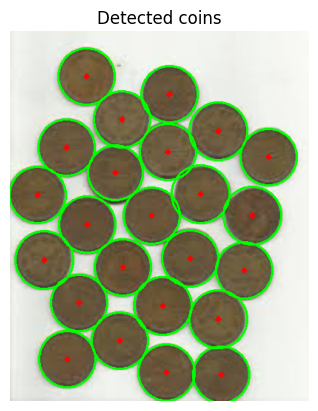

Detected circles: 24
Diameters in pixels: [np.int64(76), np.int64(76), np.int64(76), np.int64(76), np.int64(76), np.int64(76), np.int64(76), np.int64(78), np.int64(76), np.int64(78), np.int64(76), np.int64(76), np.int64(76), np.int64(78), np.int64(74), np.int64(78), np.int64(76), np.int64(78), np.int64(78), np.int64(76), np.int64(76), np.int64(76), np.int64(76), np.int64(76)]
Average diameter: 76.41666666666667


In [146]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("coins.jpeg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_rgb = cv2.resize(img_rgb, None, fx=2.0, fy=2.0)
coins_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# Canny
edges = cv2.Canny(coins_gray, 50, 150)
plt.imshow(edges, cmap="gray")
plt.title("Canny edges")
plt.axis("off")
plt.show()

# Hough circles
circles = cv2.HoughCircles(
    coins_gray,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=40,
    param1=170,
    param2=22,
    minRadius=30,
    maxRadius=40,)
output = img_rgb.copy()
if circles is not None:
    circles = np.round(circles[0, :]).astype(int)
    diameters = []
    for x, y, r in circles:
        diameters.append(2 * r)
        cv2.circle(output, (x, y), r, (0, 255, 0), 2)
        cv2.circle(output, (x, y), 2, (255, 0, 0), 3)
    plt.imshow(output)
    plt.title("Detected coins")
    plt.axis("off")
    plt.show()
    print("Detected circles:", len(circles))
    print("Diameters in pixels:", diameters)
    print("Average diameter:", np.mean(diameters))
else:
    print("No circles found")